# 05 - Final test: daily top-10 simulation (Jun-Aug 2018)
First and only use of the test period. For every calendar day, all orders approved that day are scored with
approval-time information, the 10 highest-risk orders are selected (all of them on days with fewer than 10),
and the selections are compared with eventual outcomes. Every method uses exactly the same rules.

In [1]:
# Cell 1 - make the project package importable and define folders
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["PROJECT_ROOT"] = str(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
from olist_risk import config
config.ensure_dirs()
print("PROJECT_ROOT =", PROJECT_ROOT)
print("outputs ->", config.OUTPUT_DIR)

PROJECT_ROOT = /workspace/ml_project2_v2
outputs -> /workspace/ml_project2_v2/outputs


In [2]:
# Cell 2 - load features, configuration and final models
import json, joblib
from olist_risk import policy, metrics
ft = pd.read_pickle(config.PROCESSED_DIR / "features.pkl")
exp = json.load(open(config.OUTPUT_DIR / "experiment_configs.json"))
final = {k: joblib.load(config.MODEL_DIR / f"{k}_final.joblib") for k in ["logreg", "lgbm"]}
test_pool = ft[ft.split == "test"].copy(); test_lab = test_pool[test_pool.label_available]
print(f"test pool: {len(test_pool):,} orders, {test_pool.approval_date.nunique()} days, labelled {len(test_lab):,}, "
      f"late {int((test_pool.outcome_status=='late').sum())}, undetermined {int((test_pool.outcome_status=='undetermined').sum())}")
print("proposed model:", exp["proposed_model"], "| reference rule:", exp["reference_rule"])

test pool: 18,960 orders, 88 days, labelled 18,645, late 672, undetermined 315
proposed model: logreg | reference rule: rule_longest_distance


In [3]:
# Cell 3 - score the test orders with every method
for k, m in final.items():
    test_pool[f"score_{k}"] = m.score(test_pool)
for r, f in policy.RULES.items():
    test_pool[r] = f(test_pool).values
methods = {"logreg": "score_logreg", "lgbm": "score_lgbm", **{r: r for r in policy.RULES}}
display(test_pool[["order_id", "approval_date", "score_logreg", "score_lgbm", "promised_days", "distance_km"]].head())

,order_id,approval_date,score_logreg,score_lgbm,promised_days,distance_km
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-26,0.563651,0.541326,18.0,861.035367
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08,0.264131,0.326806,27.0,514.547140
12,82566a660a982b15fb86e904c8d32918,2018-06-09,0.039368,0.050339,39.0,452.074420
13,5ff96c15d0b717ac6ad1f3d77225a350,2018-07-25,0.192013,0.268884,14.0,309.107104
15,dcb36b511fcac050b97cd5c05de84dc3,2018-06-12,0.101352,0.089266,22.0,161.208123


In [4]:
# Cell 4 - operational results under the 10-per-day cap
rows = []
for name, col in methods.items():
    rows.append({"method": name, **policy.evaluate_policy(test_pool, col)})
rnd = policy.random_policy_expectation(test_pool, n_rep=200)
rows.append({"method": "random (mean of 200 draws)", **rnd})
ops = pd.DataFrame(rows).set_index("method")
cols = ["days", "investigations", "late_identified", "unnecessary_investigations", "undetermined_selected", "late_missed",
        "pool_late", "precision", "precision_resolved", "recall_of_late", "lift_vs_random", "oracle_late_identified", "share_of_oracle", "days_with_zero_hits"]
ops[cols].to_csv(config.TABLE_DIR / "05_test_operational_comparison.csv")
display(ops[cols].round(4))

,days,investigations,late_identified,unnecessary_investigations,undetermined_selected,late_missed,pool_late,precision,precision_resolved,recall_of_late,lift_vs_random,oracle_late_identified,share_of_oracle,days_with_zero_hits
method,,,,,,,,,,,,,,
logreg,88.0,869.0,71.00,779.00,19.0,601.00,672.0,0.0817,0.0835,0.1057,2.3052,437.0,0.1625,46.00
lgbm,88.0,869.0,60.00,791.00,18.0,612.00,672.0,0.0690,0.0705,0.0893,1.9481,437.0,0.1373,48.00
rule_shortest_promise,88.0,869.0,80.00,763.00,26.0,592.00,672.0,0.0921,0.0949,0.1190,2.5974,437.0,0.1831,51.00
rule_longest_distance,88.0,869.0,34.00,823.00,12.0,638.00,672.0,0.0391,0.0397,0.0506,1.1039,437.0,0.0778,61.00
rule_highest_freight_ratio,88.0,869.0,18.00,844.00,7.0,654.00,672.0,0.0207,0.0209,0.0268,0.5844,437.0,0.0412,72.00
rule_worst_seller_history,88.0,869.0,44.00,814.00,11.0,628.00,672.0,0.0506,0.0513,0.0655,1.4286,437.0,0.1007,66.00
random (mean of 200 draws),88.0,869.0,26.45,828.05,14.5,645.55,672.0,0.0304,0.0310,0.0394,0.8588,437.0,0.0605,66.63


In [5]:
# Cell 5 - predictive metrics on the labelled test orders
pm_rows = []
for name, col in methods.items():
    pm_rows.append({"method": name, **metrics.predictive_metrics(test_lab.is_late, test_pool.loc[test_lab.index, col], probabilistic=name in final)})
pm = pd.DataFrame(pm_rows).set_index("method")
pm.to_csv(config.TABLE_DIR / "05_test_predictive_metrics.csv"); display(pm.round(4))

,n,positives,base_rate,pr_auc,roc_auc,brier,log_loss,precision_top1pct,recall_top1pct,precision_top5pct,recall_top5pct
method,,,,,,,,,,,
logreg,18645,672,0.036,0.0674,0.6250,0.0783,0.2819,0.1989,0.0551,0.0912,0.1265
lgbm,18645,672,0.036,0.0511,0.6207,0.0699,0.2607,0.0914,0.0253,0.0536,0.0744
rule_shortest_promise,18645,672,0.036,0.1309,0.7459,NaN,NaN,0.2688,0.0744,0.1792,0.2485
rule_longest_distance,18645,672,0.036,0.0315,0.3970,NaN,NaN,0.0108,0.0030,0.0472,0.0655
rule_highest_freight_ratio,18645,672,0.036,0.0310,0.4371,NaN,NaN,0.0215,0.0060,0.0204,0.0283
rule_worst_seller_history,18645,672,0.036,0.0363,0.4914,NaN,NaN,0.0054,0.0015,0.0429,0.0595


In [6]:
# Cell 6 - headline: proposed model vs reference rule vs random
P, R = exp["proposed_model"], exp["reference_rule"]
head = ops.loc[[P, R, "random (mean of 200 draws)"], ["investigations", "late_identified", "unnecessary_investigations",
                                                      "undetermined_selected", "late_missed", "precision", "recall_of_late"]]
head.to_csv(config.TABLE_DIR / "05_headline.csv"); display(head.round(3))
print(f"{P}: {int(ops.loc[P,'late_identified'])} late orders identified vs {int(ops.loc[R,'late_identified'])} for {R} "
      f"and {ops.loc['random (mean of 200 draws)','late_identified']:.1f} expected at random, using {int(ops.loc[P,'investigations'])} investigations.")

,investigations,late_identified,unnecessary_investigations,undetermined_selected,late_missed,precision,recall_of_late
method,,,,,,,
logreg,869.0,71.00,779.00,19.0,601.00,0.082,0.106
rule_longest_distance,869.0,34.00,823.00,12.0,638.00,0.039,0.051
random (mean of 200 draws),869.0,26.45,828.05,14.5,645.55,0.030,0.039


logreg: 71 late orders identified vs 34 for rule_longest_distance and 26.4 expected at random, using 869 investigations.


In [7]:
# Cell 7 - paired daily comparison: on how many days did the model beat / tie / lose to the rule?
dP = policy.daily_breakdown(test_pool, methods[P]).set_index("approval_date")
dR = policy.daily_breakdown(test_pool, methods[R]).set_index("approval_date")
diff = dP.late_identified - dR.late_identified
print(f"days model > rule: {(diff>0).sum()}, equal: {(diff==0).sum()}, model < rule: {(diff<0).sum()}")
rng = np.random.default_rng(config.SEED)
boots = [rng.choice(diff.values, len(diff)).sum() for _ in range(5000)]
ci = np.percentile(boots, [2.5, 97.5])
print(f"total extra late orders identified by the model: {diff.sum()} (95% day-bootstrap CI {ci[0]:.0f} .. {ci[1]:.0f})")
pd.DataFrame({"model_hits": dP.late_identified, "rule_hits": dR.late_identified, "diff": diff}).to_csv(config.TABLE_DIR / "05_daily_model_vs_rule.csv")

days model > rule: 30, equal: 52, model < rule: 6


total extra late orders identified by the model: 37 (95% day-bootstrap CI 21 .. 56)


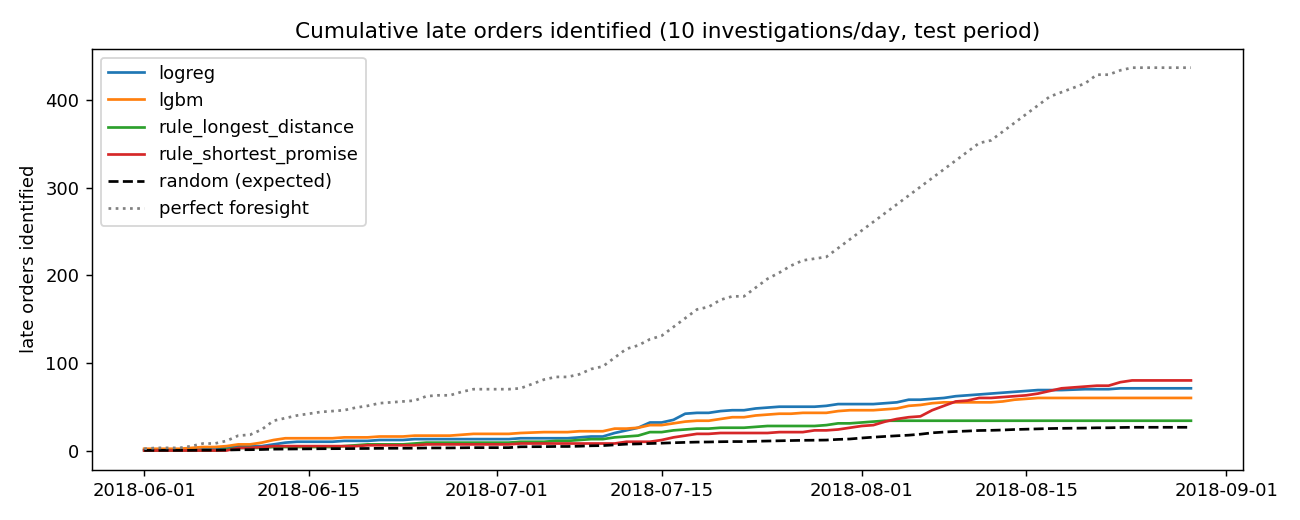

In [8]:
# Cell 8 - cumulative late orders identified over the test period
fig, ax = plt.subplots(figsize=(10, 4))
for name in [P, "lgbm" if P == "logreg" else "logreg", R, "rule_shortest_promise"]:
    d = policy.daily_breakdown(test_pool, methods[name]).set_index("approval_date")
    ax.plot(d.index, d.late_identified.cumsum(), label=name)
d = policy.daily_breakdown(test_pool, methods[P]).set_index("approval_date")
ax.plot(d.index, (d.selected * d.late_in_pool / d.orders_approved).cumsum(), "k--", label="random (expected)")
ax.plot(d.index, np.minimum(d.late_in_pool, config.DAILY_CAPACITY).cumsum(), ":", color="grey", label="perfect foresight")
ax.set_title("Cumulative late orders identified (10 investigations/day, test period)"); ax.legend(); ax.set_ylabel("late orders identified")
fig.tight_layout(); fig.savefig(config.FIG_DIR / "05_cumulative_hits_test.png", dpi=130); plt.close(fig)
display(Image(str(config.FIG_DIR / "05_cumulative_hits_test.png")))

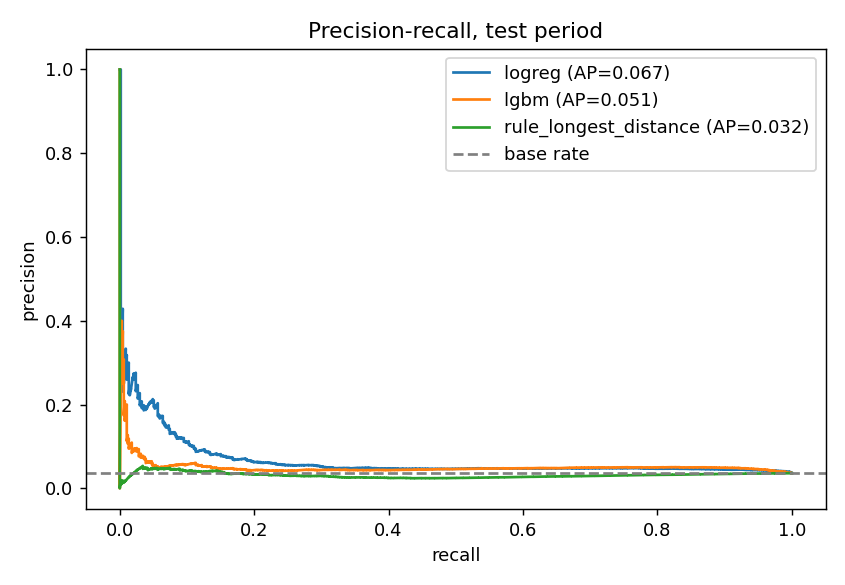

In [9]:
# Cell 9 - precision-recall curves on labelled test orders
from sklearn.metrics import precision_recall_curve
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name in ["logreg", "lgbm", R]:
    pr, rc, _ = precision_recall_curve(test_lab.is_late, test_pool.loc[test_lab.index, methods[name]])
    ax.plot(rc, pr, label=f"{name} (AP={pm.loc[name,'pr_auc']:.3f})")
ax.axhline(test_lab.is_late.mean(), color="grey", ls="--", label="base rate")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_title("Precision-recall, test period"); ax.legend()
fig.tight_layout(); fig.savefig(config.FIG_DIR / "05_pr_curves_test.png", dpi=130); plt.close(fig)
display(Image(str(config.FIG_DIR / "05_pr_curves_test.png")))

In [10]:
# Cell 10 - save the daily prioritisation list for the test period (traceable to order_id + approval date)
sel = policy.select_daily_topk(test_pool, methods[P])
out = sel[sel.selected][["approval_date", "daily_rank", "order_id", "order_approved_at", methods[P], "customer_id", "main_seller_id",
                          "customer_state", "seller_state", "main_category", "promised_days", "distance_km", "order_estimated_delivery_date",
                          "outcome_status", "is_late", "days_late", "order_status"]].rename(columns={methods[P]: "risk_score"})
out.insert(0, "policy", f"{P}_top{config.DAILY_CAPACITY}")
out.to_csv(config.OUTPUT_DIR / "daily_prioritization_test.csv", index=False)
selR = policy.select_daily_topk(test_pool, methods[R])
selR[selR.selected][["approval_date", "daily_rank", "order_id", "order_approved_at", R, "outcome_status", "is_late"]].to_csv(
    config.OUTPUT_DIR / "daily_prioritization_test_rule.csv", index=False)
print(out.shape, "rows saved to outputs/daily_prioritization_test.csv"); display(out.head(12))

(869, 18) rows saved to outputs/daily_prioritization_test.csv


,policy,approval_date,daily_rank,order_id,order_approved_at,risk_score,customer_id,main_seller_id,customer_state,seller_state,main_category,promised_days,distance_km,order_estimated_delivery_date,outcome_status,is_late,days_late,order_status
36606,logreg_top10,2018-06-01,1,05bef443b850685058070c9e781988e8,2018-06-01 10:52:26,0.475168,4ff3f3945300d8e040f2906998401e92,f5a590cf36251cf1162ea35bef76fe84,MA,SP,musical_instruments,34.0,2373.097745,2018-07-05,on_time,0.0,-9.0,delivered
13201,logreg_top10,2018-06-01,2,08d862895d238cb8405dffe9b981df25,2018-06-01 20:11:26,0.401890,83e1602374f1c008027bbf8828fc785b,1025f0e2d44d7041d6cf58b6550e0bfa,RJ,SP,furniture_decor,34.0,276.275431,2018-07-05,on_time,0.0,-21.0,delivered
60681,logreg_top10,2018-06-01,3,6ded814a50d02c15369b8b7fdff6a3e5,2018-06-01 18:11:15,0.381379,96c221428626e9522b8df0d8af8c9b57,a420f60ff1aa9acc80d0e42959f2b313,AL,SP,baby,48.0,2022.298825,2018-07-19,on_time,0.0,-15.0,delivered
94704,logreg_top10,2018-06-01,4,b2e66035b66649e5b359d5b33ba09c21,2018-06-01 11:12:16,0.288708,9ea4c5abbde4a7a943a9fb80a85176c3,16090f2ca825584b5a147ab24aa30c86,RJ,SP,auto,34.0,352.254694,2018-07-05,on_time,0.0,-23.0,delivered
31447,logreg_top10,2018-06-01,5,a3387455ec2a51ea33eb1d7557994979,2018-06-01 13:12:38,0.286921,64bfeb705b436477f84efa0fd4623dc1,9e7c5f4d7770eab65738cca38f9efccf,PI,SP,toys,28.0,2088.866022,2018-06-29,on_time,0.0,-21.0,delivered
85361,logreg_top10,2018-06-01,6,9bd2f19fdebcf5928f0971caeac464d9,2018-06-01 07:42:11,0.273257,3dfb839c63ae6b7545b643714e1b6dc3,f7ba60f8c3f99e7ee4042fdef03b70c4,CE,SP,health_beauty,47.0,2344.277493,2018-07-18,on_time,0.0,-33.0,delivered
99236,logreg_top10,2018-06-01,7,090d23542dd542b9a9e25fa9d5d9e528,2018-06-01 14:52:02,0.261244,73d09f34ade23726e0b2388af3b357e4,5670f4db5b62c43d542e1b2d56b0cf7c,PI,SP,perfumery,46.0,1966.172427,2018-07-17,on_time,0.0,-33.0,delivered
492,logreg_top10,2018-06-01,8,d4ab8a264235be36f72a07621046d082,2018-06-01 15:52:33,0.243029,7a5846ef7b6f7d58630bb4b0aafe2858,fa1c13f2614d7b5c4749cbc52fecda94,RJ,SP,watches_gifts,41.0,549.373447,2018-07-12,on_time,0.0,-30.0,delivered
23885,logreg_top10,2018-06-01,9,ea639b1119b066a5966041d2367ce1e7,2018-06-01 20:11:23,0.240065,2a8e6bb4efdcf4ac252e81658f1eb003,34056b8b55c1775a22af2331670a799c,BA,SP,auto,42.0,1551.934028,2018-07-13,late,1.0,3.0,delivered
62730,logreg_top10,2018-06-01,10,8898a51e0e6b578277a7c20d5b31877b,2018-06-01 10:11:33,0.219726,17298835e7756f3763fac2562d2adf33,232a6014e7b10cba61c6c2b2ea6bb4b0,PI,SP,pet_shop,42.0,2001.639787,2018-07-13,on_time,0.0,-22.0,delivered


In [11]:
# Cell 11 - how were days with fewer than 10 orders and undetermined outcomes handled?
db = policy.daily_breakdown(test_pool, methods[P]); db.to_csv(config.TABLE_DIR / "05_daily_breakdown_proposed.csv", index=False)
print("days in test:", len(db), "| days with < 10 approved orders:", int((db.orders_approved < 10).sum()),
      "| investigations used:", int(db.selected.sum()), "of", 10 * len(db), "possible")
print("selected orders with undetermined outcome (canceled/unavailable/not delivered):", int(db.undetermined_selected.sum()))
display(db.describe().round(2))
# Sensitivity for incomplete outcomes (right-censoring at the data export, 2018-10-17): an undelivered order that was not
# canceled/unavailable (still open: shipped/invoiced/processing/approved/created) and was already past its promised date at export is at least overdue -> count it as a delivery problem.
export_ts = ft.order_purchase_timestamp.max()
adj_status, open_overdue = policy.censoring_adjusted_status(test_pool, export_ts)
print(f"data export: {export_ts} | test orders undetermined: {int((test_pool.outcome_status == 'undetermined').sum())}, "
      f"of which still open (shipped/invoiced/processing/approved/created) and past the promised date at export: {int(open_overdue.sum())}")
tp_adj = test_pool.assign(outcome_status=adj_status)
cs = []
for name, col in methods.items():
    e0, e1 = policy.evaluate_policy(test_pool, col), policy.evaluate_policy(tp_adj, col)
    cs.append({"method": name, "late_identified_main": e0["late_identified"], "problems_identified_censoring_adjusted": e1["late_identified"],
               "precision_main": e0["precision"], "precision_censoring_adjusted": e1["precision"],
               "problems_in_pool_adjusted": e1["pool_late"], "undetermined_selected_adjusted": e1["undetermined_selected"]})
cs = pd.DataFrame(cs).set_index("method"); cs.to_csv(config.TABLE_DIR / "05_censoring_sensitivity.csv"); display(cs.round(4))

days in test: 88 | days with < 10 approved orders: 2 | investigations used: 869 of 880 possible
selected orders with undetermined outcome (canceled/unavailable/not delivered): 19


,approval_date,orders_approved,late_in_pool,selected,late_identified,unnecessary,undetermined_selected
count,88,88.00,88.00,88.00,88.00,88.00,88.00
mean,2018-07-15 05:43:38.181818112,215.45,7.64,9.88,0.81,8.85,0.22
min,2018-06-01 00:00:00,4.00,0.00,4.00,0.00,3.00,0.00
25%,2018-06-22 18:00:00,148.50,1.00,10.00,0.00,8.00,0.00
50%,2018-07-15 12:00:00,210.50,3.50,10.00,0.00,9.00,0.00
75%,2018-08-06 06:00:00,282.75,10.25,10.00,1.00,10.00,0.00
max,2018-08-29 00:00:00,697.00,71.00,10.00,7.00,10.00,2.00
std,NaN,102.19,10.56,0.83,1.25,1.50,0.49


data export: 2018-10-17 17:30:18 | test orders undetermined: 315, of which still open (shipped/invoiced/processing/approved/created) and past the promised date at export: 191


,late_identified_main,problems_identified_censoring_adjusted,precision_main,precision_censoring_adjusted,problems_in_pool_adjusted,undetermined_selected_adjusted
method,,,,,,
logreg,71,86,0.0817,0.0990,863,4
lgbm,60,77,0.0690,0.0886,863,1
rule_shortest_promise,80,89,0.0921,0.1024,863,17
rule_longest_distance,34,45,0.0391,0.0518,863,1
rule_highest_freight_ratio,18,24,0.0207,0.0276,863,1
rule_worst_seller_history,44,51,0.0506,0.0587,863,4
